## A/B - тестирование


Внутри увидите пример как формируются результаты по аб-тестированию. Прочтите сначала его, затем приступайте к выполнению задания.

В папке присутствует файл ab_test_ensembles.csv , который содержит реальные данные ab теста, когда-то проходившего у меня. Вам необходимо провести стандартный пайплайн, начав с ознакомления данных до вывода отчета. Условие гипотезы такое же как и в примере, нам необходимо нашим новым вариантом увеличить коэффициент конверсии на 2%, коэффициенты конверсии одинаковы с файлом из примера (плюс/минус) поэтому с этим проблем быть не должно. Условия гипотез теже.

В A/B тесте было два варианта работы сервиса - standard и svm_ensemble_v_1_22, где работала модель классификации пользователей.

Ответьте на 2 вопроса:

1. Стоит ли нам оставить старый вариант работы или заменить на вариант svm_ensemble_v_1_22 (используем всю выборку 200к+ записей)
2. Так же посчитайте вывод для типа пользователей (user_type) стоит ли для новых/старых пользователей (new/registered user) оставить старый / новый вариант работы (разделяем всю выборку 200к+ записей на группы)

Также необходимо провести небольшое EDA по представленному датасету, нарисовать два графика на ваш вкус.

---

**Баллы могут быть снижены** за качество кода - старайтесь чтобы код был максимально лаконичным. Названия переменных (если они используются) должны отражать максимальную ее сущность.

**Комментарии по сдаче практического задания**:
1. Залить в репу на github в папку module_2/ab_test_inference
2. Ссылку на репо отправлять мне в тг не позднее дедлайна.
3. Тема письма: Домашнее задание по модулю 2 <Фамилия Имя>
4. После дедлайна, неотправленные задания, оцениваются максимум в 7 баллов.

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

In [2]:
df = pd.read_csv('ab_test_ensembles.csv')
df.head()

,user_id,timestamp,group,variants,converted,location,age_group,user_type
0,9109b0dc-d393-497f-8d63-ba9a25dd16b4,2022-05-21 22:11:48.556739,control,standard,0,United Kingdom,18-25,registered_user
1,2430c3d2-f75b-4b31-8271-51b6a76c2652,2022-05-12 08:01:45.159739,control,standard,0,United Kingdom,42-49,registered_user
2,44788c4e-8dd2-4fad-b986-75e76f4adb64,2022-05-11 16:55:06.154213,treatment,svm_ensemble_v_1_22,0,United Kingdom,26-33,new_user
3,4699a417-506d-41b8-a354-6af6ad576963,2022-05-08 18:28:03.143765,treatment,svm_ensemble_v_1_22,0,United Kingdom,42-49,registered_user
4,304b0d28-bcdf-401a-9dff-66230d3ba0bc,2022-05-21 01:52:26.210827,control,standard,1,United Kingdom,42-49,registered_user


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   user_id    294478 non-null  str  
 1   timestamp  294478 non-null  str  
 2   group      294478 non-null  str  
 3   variants   294478 non-null  str  
 4   converted  294478 non-null  int64
 5   location   294478 non-null  str  
 6   age_group  294478 non-null  str  
 7   user_type  294478 non-null  str  
dtypes: int64(1), str(7)
memory usage: 18.0 MB


In [4]:
pd.crosstab(df['group'], df['variants'])

variants,standard,svm_ensemble_v_1_22
group,,
control,145274,1928
treatment,1965,145311


In [5]:
user_counts = df['user_id'].value_counts()
duplicate_users = user_counts[user_counts > 1].count()
print(f'Число повторяющихся пользователей: {duplicate_users}')

Число повторяющихся пользователей: 0


In [6]:
df['converted'].value_counts()

converted
0    259241
1     35237
Name: count, dtype: int64

In [7]:
conversion_rates = df.groupby('group')['converted']

std = lambda x: np.std(x, ddof=0)
sem = lambda x: stats.sem(x, ddof=0)

conversion_rates = conversion_rates.agg([np.mean, std, sem]).rename(columns={'mean':'CR mean', '<lambda_0>':'CR std', '<lambda_1>':'CR se'})
print('All users')
conversion_rates

All users


,CR mean,CR std,CR se
group,,,
control,0.120399,0.325428,0.000848
treatment,0.118920,0.323694,0.000843


In [8]:
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

control_result = df[df['group'] == 'control']['converted']
treatment_result = df[df['group'] == 'treatment']['converted']

successes = [control_result.sum(), treatment_result.sum()]
nobs = [control_result.count(), treatment_result.count()]

z_stat, p_val = proportions_ztest(successes, nobs=nobs)
(low_con, low_treat), (up_con, up_treat) = proportion_confint(successes, nobs=nobs, alpha=0.05)

print(f'Z-statistic: {z_stat:.2f}')
print(f'p-value: {p_val:.3f}')
print(f'CI 95% for control group: [{low_con:.3f}, {up_con:.3f}]')
print(f'CI 95% for treatment group: [{low_treat:.3f}, {up_treat:.3f}]')

Z-statistic: 1.24
p-value: 0.216
CI 95% for control group: [0.119, 0.122]
CI 95% for treatment group: [0.117, 0.121]


P-value = 0.216, что значительно превышает уровень значимости 0.05. Z-статистика не превышает критического значения 1.96. Полученные результаты не позволяют нам отклонить нулевую гипотезу, согласно которой конверсии двух вариантов статистически не различаются.

Более того, показатель конверсии контрольной группы (12.04%) оказался несколько выше конверсии экспериментальной группы (11.89%). Тем не менее, полученная разница не является статистически значимой и может быть объяснена влиянием случайных факторов.

Рекомендация: оставить текущий вариант. В случае, если будет обнаружен положительный эффект по другим значимым для бизнеса метрикам, модель классификации пользователей можно внедрить, поскольку статистически значимого влияния на конверсию не обнаружено.

In [9]:
pd.crosstab(df['user_type'], df['group'])

group,control,treatment
user_type,,
new_user,73750,73488
registered_user,73452,73788


In [10]:
new = df[df['user_type'] == 'new_user']

new_conversion_rates = new.groupby('group')['converted']
new_conversion_rates = new_conversion_rates.agg([np.mean, std, sem]).rename(columns={'mean':'CR mean', '<lambda_0>':'CR std', '<lambda_1>':'CR se'})

print('New users')
new_conversion_rates

New users


,CR mean,CR std,CR se
group,,,
control,0.120746,0.325832,0.001200
treatment,0.117557,0.322082,0.001188


In [11]:
reg = df[df['user_type'] == 'registered_user']

reg_conversion_rates = reg.groupby('group')['converted']
reg_conversion_rates = reg_conversion_rates.agg([np.mean, std, sem]).rename(columns={'mean':'CR mean', '<lambda_0>':'CR std', '<lambda_1>':'CR se'})

print('Registered users')
reg_conversion_rates

Registered users


,CR mean,CR std,CR se
group,,,
control,0.120051,0.325021,0.001199
treatment,0.120277,0.325285,0.001197


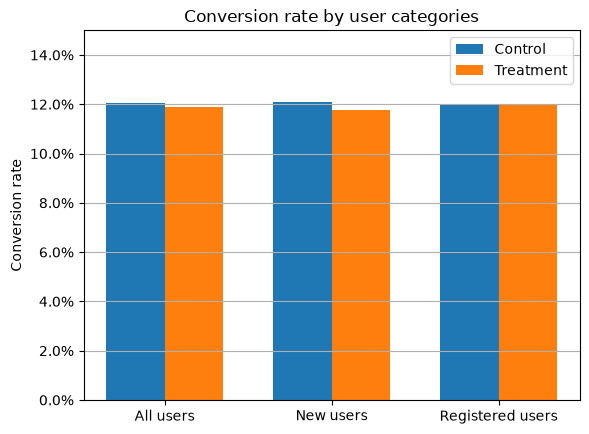

In [12]:
categories = ['All users', 'New users', 'Registered users']

control = [
    conversion_rates.loc['control', 'CR mean'],
    new_conversion_rates.loc['control', 'CR mean'],
    reg_conversion_rates.loc['control', 'CR mean']
]

treatment = [
    conversion_rates.loc['treatment', 'CR mean'],
    new_conversion_rates.loc['treatment', 'CR mean'],
    reg_conversion_rates.loc['treatment', 'CR mean']
]

x = np.arange(len(categories))
width = 0.35

plt.bar(x - width/2, control, width, label='Control')
plt.bar(x + width/2, treatment, width, label='Treatment')

plt.xticks(x, categories)
plt.ylim(0, 0.15)
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
plt.ylabel('Conversion rate')
plt.title('Conversion rate by user categories')
plt.legend()
plt.grid(axis='y')

In [13]:
new_control_result = new[new['group'] == 'control']['converted']
new_treatment_result = new[new['group'] == 'treatment']['converted']

new_successes = [new_control_result.sum(), new_treatment_result.sum()]
new_nobs = [new_control_result.count(), new_treatment_result.count()]

new_z_stat, new_p_val = proportions_ztest(new_successes, nobs=new_nobs)
(new_low_con, new_low_treat), (new_up_con, new_up_treat) = proportion_confint(new_successes, nobs=new_nobs, alpha=0.05)

print(f'Z-statistic for new users: {new_z_stat:.2f}')
print(f'p-value for new users: {new_p_val:.3f}')
print(f'CI 95% for control group for new users: [{new_low_con:.3f}, {new_up_con:.3f}]')
print(f'CI 95% for treatment group for new users: [{new_low_treat:.3f}, {new_up_treat:.3f}]')


Z-statistic for new users: 1.89
p-value for new users: 0.059
CI 95% for control group for new users: [0.118, 0.123]
CI 95% for treatment group for new users: [0.115, 0.120]


P-value = 0.059, что близко к уровню значимости 0.05, но все же превышает его. Z-статистика не превышает критического значения 1.96, хотя также близка к нему. Полученные результаты не позволяют нам отклонить нулевую гипотезу, согласно которой конверсии двух вариантов статистически не различаются.

Показатель конверсии контрольной группы (12.07%) оказался несколько выше конверсии экспериментальной группы (11.76%). Полученная разница не является статистически значимой и может быть объяснена влиянием случайных факторов, однако p-value близко к установленному порогу.

Рекомендация: оставить текущий вариант для новых пользователей. Несмотря на отсутствие статистически значимого различия, наблюдаемая разница в конверсии имеет отрицательное направление. Рекомендуется провести дополнительное исследование, чтобы проверить, не оказывает ли новый вариант негативного влияния на конверсию новых пользователей.

In [14]:
reg_control_result = reg[reg['group'] == 'control']['converted']
reg_treatment_result = reg[reg['group'] == 'treatment']['converted']

reg_successes = [reg_control_result.sum(), reg_treatment_result.sum()]
reg_nobs = [reg_control_result.count(), reg_treatment_result.count()]

reg_z_stat, reg_p_val = proportions_ztest(reg_successes, nobs=reg_nobs)
(reg_low_con, reg_low_treat), (reg_up_con, reg_up_treat) = proportion_confint(reg_successes, nobs=reg_nobs, alpha=0.05)

print(f'Z-statistic for registered users: {reg_z_stat:.2f}')
print(f'p-value for registered users: {reg_p_val:.3f}')
print(f'CI 95% for control group for registered users: [{reg_low_con:.3f}, {reg_up_con:.3f}]')
print(f'CI 95% for treatment group for registered users: [{reg_low_treat:.3f}, {reg_up_treat:.3f}]')

Z-statistic for registered users: -0.13
p-value for registered users: 0.894
CI 95% for control group for registered users: [0.118, 0.122]
CI 95% for treatment group for registered users: [0.118, 0.123]


P-value = 0.894, что значительно превышает уровень значимости 0.05. Z-статистика по абсолютному значению значительно меньше критического значения 1.96. Полученные результаты не позволяют нам отклонить нулевую гипотезу, согласно которой конверсии двух вариантов статистически не различаются.

Показатель конверсии контрольной группы (12.01%) оказался практически равным конверсии экспериментальной группы (12.03%). Полученная разница не является статистически значимой и может быть объяснена влиянием случайных факторов.

Рекомендация: оставить текущий вариант. В случае, если будет обнаружен положительный эффект по другим значимым для бизнеса метрикам, модель классификации пользователей можно внедрить, поскольку статистически значимого влияния на конверсию среди зарегистрированных пользователей не обнаружено.

In [15]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
np.max(df['timestamp']), np.min(df['timestamp'])

(Timestamp('2022-05-24 13:41:54.460509'),
 Timestamp('2022-05-02 13:42:05.378582'))

In [16]:
df.groupby([df['timestamp'].dt.date, df['user_type']])['user_id'].count()

timestamp   user_type      
2022-05-02  new_user           2893
            registered_user    2890
2022-05-03  new_user           6693
            registered_user    6701
2022-05-04  new_user           6554
            registered_user    6730
2022-05-05  new_user           6515
            registered_user    6609
2022-05-06  new_user           6744
            registered_user    6784
2022-05-07  new_user           6638
            registered_user    6743
2022-05-08  new_user           6645
            registered_user    6919
2022-05-09  new_user           6750
            registered_user    6689
2022-05-10  new_user           6861
            registered_user    6662
2022-05-11  new_user           6827
            registered_user    6726
2022-05-12  new_user           6617
            registered_user    6705
2022-05-13  new_user           6693
            registered_user    6545
2022-05-14  new_user           6760
            registered_user    6569
2022-05-15  new_user           6661


Для оценки равномерности распределения наблюдений во времени проверено количество пользователей каждого типа по дням.

Количество наблюдений в целом стабильно на протяжении периода. Однако, в первый и последний дни наблюдений примерно в два раза меньше, чем в остальные. Эти даты охватывают неполные дни. Если почасовые конверсии отличаются, это будет искажать истинные результаты при построении графика по дням недели. Поэтому первый и последний дни решено исключить при построении графика конверсии по дням недели.

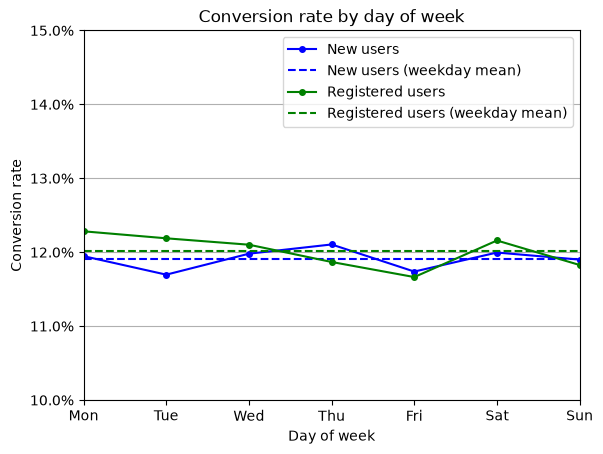

In [17]:
df_without_two_days = df[(df['timestamp'] >= pd.Timestamp('2022-05-03')) & (df['timestamp'] < pd.Timestamp('2022-05-24'))]
day_of_week_conversion = df_without_two_days.groupby([df_without_two_days['timestamp'].dt.day_of_week, df_without_two_days['user_type']])['converted'].mean()
day_of_week_conversion = day_of_week_conversion.unstack()
plt.xlim(0, 6)
plt.xlabel('Day of week')
plt.xticks(range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.ylim(0.10, 0.15)
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
plt.ylabel('Conversion rate')
plt.title('Conversion rate by day of week')
plt.grid(axis='y')
plt.plot(day_of_week_conversion['new_user'], marker='o', markersize=4, label='New users', color='blue')
plt.axhline(day_of_week_conversion['new_user'].mean(), color='blue', linestyle='--', label='New users (weekday mean)')
plt.plot(day_of_week_conversion['registered_user'], marker='o', markersize=4, label='Registered users', color='green')
plt.axhline(day_of_week_conversion['registered_user'].mean(), color='green', linestyle='--', label='Registered users (weekday mean)')
plt.legend();

Для наглядности ось Y ограничена диапазоном от 10% до 15%, что позволяет лучше рассмотреть небольшие колебания конверсии.

На графике наблюдаются небольшие колебания конверсии в зависимости от дня недели. Выраженной зависимости конверсии от дня недели не прослеживается. Конверсии новых и зарегистрированных пользователей различаются незначительно. При этом у зарегистрированных пользователей в большинстве дней конверсия несколько выше.